In [1]:
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import warnings

warnings.filterwarnings("ignore")

SEED = 987

DIR_ROOT = Path.cwd().parent.parent
sys.path.insert(0, str(DIR_ROOT))

%load_ext autoreload
%autoreload 2

In [2]:
import data

listings = data.load("listings")
off_market = data.load("off_market")
list_aware = data.load("list_aware")

df = listings.copy()

In [4]:
from notebooks.xxbonkxx.models import baseline_features

df["house_area"] = baseline_features.square_feet(df["house_area"])
df["month"] = baseline_features.make_months(listings)
df["day"] = baseline_features.make_days(listings)
df["year"] = baseline_features.make_years(listings)
df["is_apartment"] = baseline_features.make_is_apartment(listings)
df["price_per_sqft"] = df["sold_price"] / df["house_area"]
df["log_price_per_sqft"] = np.log(df["price_per_sqft"])

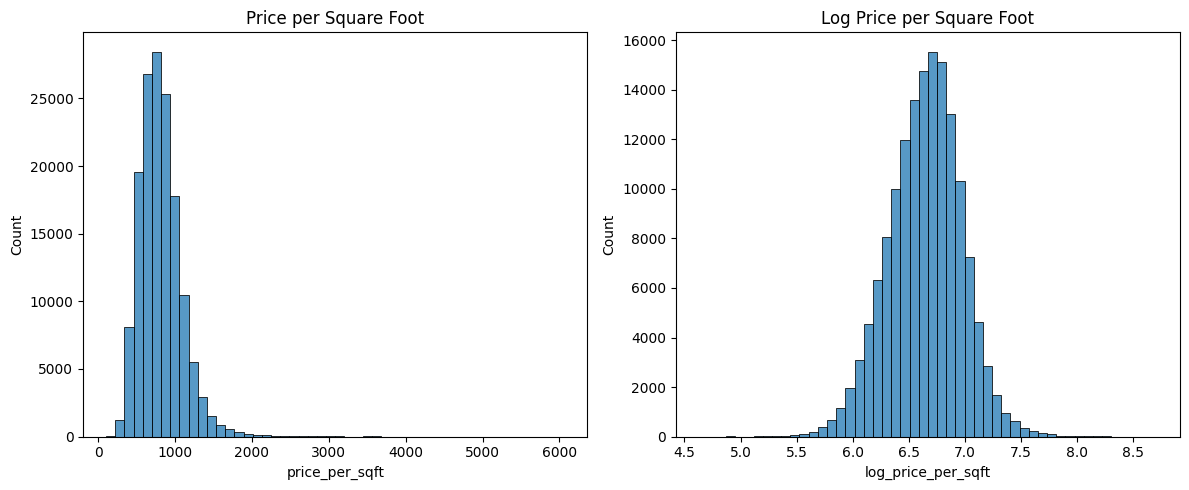

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(df["price_per_sqft"], bins=50, ax=axes[0])
axes[0].set_title("Price per Square Foot")
sns.histplot(df["log_price_per_sqft"], bins=50, ax=axes[1])
axes[1].set_title("Log Price per Square Foot")
plt.tight_layout()
plt.show()